In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
from tqdm import tqdm

from pathlib import Path

current_file_path = Path().resolve().parent
current_file_path

PosixPath('/home/mag/variance-analysis')

## Load in trajectory data

In [2]:
# load in traj data

import pandas as pd

dataset = 6
session = 'A1821-190910' #'A1824-190827'

data_path = current_file_path / f'data/dusz/Dataset_{dataset}' / session / 'Data'

positions = pd.read_csv(data_path / 'Tracking_data.csv')
positions.columns = ['timestamp', 'x', 'y', 'hd', 'pitch', 'roll']

positions

,timestamp,x,y,hd,pitch,roll
0,3044.968,-0.130861,0.100300,33.84858,-35.82468,0.539701
1,3044.978,-0.130832,0.100818,34.52600,-36.17565,1.159622
2,3044.988,-0.130896,0.101376,35.51010,-36.44134,1.384442
3,3044.998,-0.130989,0.101857,35.95627,-35.95127,2.098573
4,3045.008,-0.131249,0.102067,35.85831,-36.34102,2.746262
...,...,...,...,...,...,...
541520,11547.110,0.228479,0.181418,46.24308,44.69220,23.492130
541521,11547.120,0.228509,0.181343,46.41534,44.59696,23.677580
541522,11547.130,0.228535,0.181324,46.83366,44.50164,23.561010
541523,11547.140,0.228546,0.181349,47.37060,44.32819,23.070700


In [3]:
from scipy.io.matlab._mio5_params import mat_struct
from scipy.io import loadmat

# make sure to filter by epochs
def extract_matlab_obj(obj):
    """
    Recursively extract MATLAB structs into Python dictionaries and arrays.
    """
    if not (isinstance(obj, mat_struct) or isinstance(obj, dict)):
        return obj

    out = {}
    obj = obj.__dict__ if isinstance(obj, mat_struct) else obj

    for key, val in obj.items():
        # Skip metadata
        if key in ['_fieldnames', 'type', 'time_unit', 'data_unit', 'name']:
            continue

        if isinstance(val, mat_struct) or isinstance(val, dict):
            out[key] = extract_matlab_obj(val)
        elif isinstance(val, np.ndarray):
            arr = []
            for v in val:
                arr.append(extract_matlab_obj(v))
            out[key] = np.array(arr)
        else:
            out[key] = val

    return out

epochs = loadmat(data_path / 'BehavEpochs.mat', struct_as_record=False, squeeze_me=True)
if dataset == 6:
    epoch_data = extract_matlab_obj(epochs['wakeEp'])
else:
    epoch_data = extract_matlab_obj(epochs['wake1Ep'])


In [4]:


# filter by epoch
positions = positions[['timestamp', 'x', 'y', 'hd']].to_numpy()
position_mask = (positions[:, 0] > epoch_data['start']) & (positions[:, 0] < epoch_data['stop'])
positions = positions[position_mask]

# normalize x/y positions to be positive
positions[:, 1] += abs(np.min(positions[:, 1]))
positions[:, 2] += abs(np.min(positions[:, 2]))

len(positions)

270168

In [5]:
# Load in velocity data
velocity_data = []
vel_path = current_file_path / f'data/dusz/Dataset_{dataset}' / session / 'Data/Velocity.mat'
velocity_data = loadmat(vel_path, struct_as_record=False, squeeze_me=True)
        
velocity_data = extract_matlab_obj(velocity_data['vel'])
velocity_data = np.dstack((velocity_data['t'], velocity_data['data']))[0]
mask = (velocity_data[:, 0] > epoch_data['start']) & (velocity_data[:, 0] < epoch_data['stop'])
velocity_data = velocity_data[mask]

# velocity_data has shape (M, 3): [t, vx, vy] where speed = sqrt(vx**2 + vy**2)
vel_t   = velocity_data[:, 0]
vel_xy  = velocity_data[:, 1:3]
speed   = np.linalg.norm(vel_xy, axis=1)          # cm s-¹ I think this is unnecessary lol

# Interpolate speed at each position timestamp
pos_t   = positions[:, 0]
speed_at_pos = np.interp(pos_t, vel_t, speed, left=np.nan, right=np.nan)

speed_thresh = 5.0                               # cm s-¹
slow_mask = speed_at_pos < speed_thresh          # True where animal is < 5 cm/s

#positions[slow_mask, 1:3] = np.nan               # NaN-out slow periods
#positions[slow_mask, 3:] = np.nan
positions = positions[~slow_mask]


In [6]:
# calculate movement direction

def get_md_from_xy(positions, smoothing_window=140):
    def rolling_mean(positions):
        kernel = np.ones(smoothing_window) / smoothing_window
        return np.convolve(positions, kernel, mode='same')
        
    x = rolling_mean(positions[:, 1])
    y = rolling_mean(positions[:, 2])
    
    dx = x[1:] - x[:-1]
    dy = y[1:] - y[:-1]

    direction = np.degrees(np.arctan2(dy, dx))
    direction = (direction + 360) % 360

    direction = np.concatenate([direction, [direction[-1]]])

    return direction

# get hd and md
hd = positions[:, 3]
hd = (hd + 360) % 360

md = get_md_from_xy(positions)


In [7]:
stimulus_type = "xy"

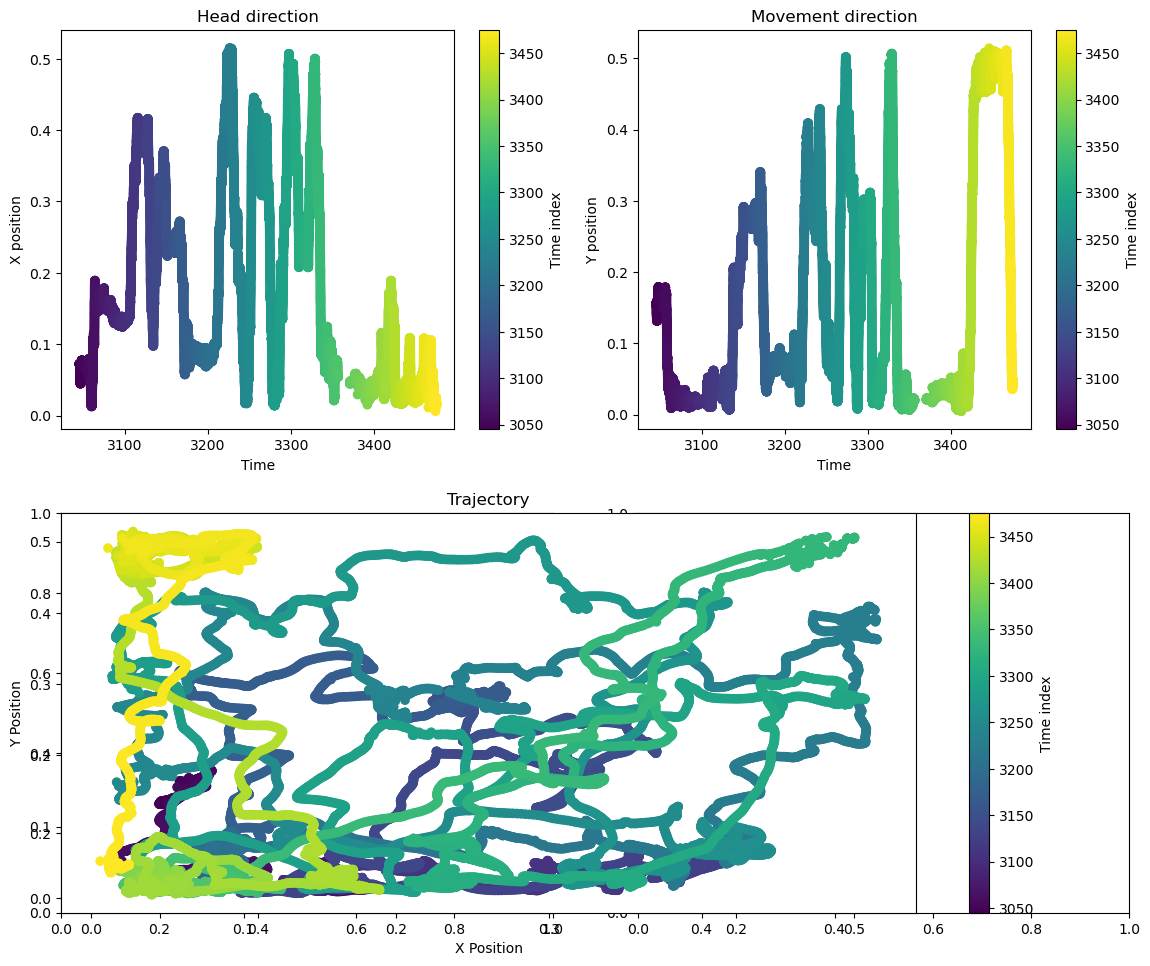

In [8]:
# display position trajectory, head direction, movement direction

if stimulus_type == 'xy':
    stimuli = (positions[:, 1], positions[:, 2])
    labels = ("X position", "Y position")
    limits = (0, max(np.max(stimuli[0]), np.max(stimuli[1])))
else:
    stimuli = (hd, md)
    labels = ("HD (degrees)", "MD (degrees)")
    limits = (0, 360)

time_window = 30000

timesteps = positions[:time_window, 0]

# Create subplots
fig, axes = plt.subplots(2, 2, figsize=(12, 10), gridspec_kw={'height_ratios': [1, 1]})

# Head direction plot (top left)
sc = axes[0, 0].scatter(timesteps, stimuli[0][:time_window], 
                        c=timesteps[:time_window], cmap='viridis')
cbar = fig.colorbar(sc, ax=axes[0, 0])
cbar.set_label("Time index")
axes[0, 0].set_xlabel("Time")
axes[0, 0].set_ylabel(labels[0])
axes[0, 0].set_title("Head direction")

# Movement direction plot (top right)
sc = axes[0, 1].scatter(timesteps, stimuli[1][:time_window], 
                        c=timesteps[:time_window], cmap='viridis')
cbar = fig.colorbar(sc, ax=axes[0, 1])
cbar.set_label("Time index")
axes[0, 1].set_xlabel("Time")
axes[0, 1].set_ylabel(labels[1])
axes[0, 1].set_title("Movement direction")

# Trajectory plot (bottom, spanning both columns)
ax_traj = fig.add_subplot(2, 1, 2)
sc = ax_traj.scatter(stimuli[0][:time_window], stimuli[1][:time_window], 
                     c=timesteps[:time_window], cmap='viridis')
cbar = fig.colorbar(sc, ax=ax_traj)
cbar.set_label("Time index")
ax_traj.set_xlabel("X Position")
ax_traj.set_ylabel("Y Position")
ax_traj.set_title("Trajectory")

# Adjust layout
plt.tight_layout()
plt.show()

## Define ideal tuning curve

In [9]:
import numpy as np
import scipy.stats # Required for Method 3

def get_samples_multivariate_normal(num_samples_total, limits, num_bins,
                                    correlation_coefficient, dead_center=True,
                                    s1_std_factor=4, s2_std_factor=4):
    s_min, s_max = limits[0], limits[1]

    mean_s1 = (s_min + s_max) / 2
    mean_s2 = (s_min + s_max) / 2
    std_s1 = (s_max - s_min) / s1_std_factor
    std_s2 = (s_max - s_min) / s2_std_factor

    mean_vec = [mean_s1, mean_s2]
    cov_matrix = [
        [std_s1**2, correlation_coefficient * std_s1 * std_s2],
        [correlation_coefficient * std_s1 * std_s2, std_s2**2]
    ]

    s1_continuous, s2_continuous = np.random.multivariate_normal(mean_vec, cov_matrix, num_samples_total).T

    # Clip to ensure stimuli are within bounds (MVN can produce values outside)
    s1_continuous = np.clip(s1_continuous, s_min, s_max)
    s2_continuous = np.clip(s2_continuous, s_min, s_max)

    s1_bins = np.linspace(s_min, s_max, num_bins + 1)
    s2_bins = np.linspace(s_min, s_max, num_bins + 1)

    if dead_center:
        # Digitize: find which bin each sample falls into. Indices are 1-based.
        s1_bin_indices = np.digitize(s1_continuous, s1_bins[1:-1]) # Use interior bins for digitize
        s2_bin_indices = np.digitize(s2_continuous, s2_bins[1:-1])

        # np.digitize behavior: bins[i-1] <= x < bins[i]. Index i is returned.
        # We want 0-based index for our bins array.
        # Example: if s1_bins = [0, 0.1, 0.2], bins[1:-1] is [0.1].
        # val 0.05 -> digitize -> 0. val 0.15 -> digitize -> 1.
        # Need to adjust for 0-based indexing if using s1_bins[idx]
        # A simpler way for dead_center:
        s1_bin_indices_0based = np.searchsorted(s1_bins, s1_continuous, side='right') - 1
        s2_bin_indices_0based = np.searchsorted(s2_bins, s2_continuous, side='right') - 1

        s1_bin_indices_0based = np.clip(s1_bin_indices_0based, 0, num_bins - 1)
        s2_bin_indices_0based = np.clip(s2_bin_indices_0based, 0, num_bins - 1)

        s1_pois = (s1_bins[s1_bin_indices_0based] + s1_bins[s1_bin_indices_0based + 1]) / 2
        s2_pois = (s2_bins[s2_bin_indices_0based] + s2_bins[s2_bin_indices_0based + 1]) / 2
    else:
        s1_pois = s1_continuous
        s2_pois = s2_continuous

    occ_grid, _, _ = np.histogram2d(s1_pois, s2_pois, bins=[s1_bins, s2_bins])
    occ_grid = occ_grid.astype(int)

    return s1_pois, s2_pois, occ_grid, s1_bins, s2_bins

def get_samples_conditional_copula(num_samples_total, limits, num_bins,
                                   target_correlation, dead_center=True):
    """
    Generates correlated samples using a Gaussian copula approach.
    The marginal distributions will be uniform.

    Args:
        num_samples_total (int): Total number of (s1, s2) pairs.
        limits (list or tuple): [min_val, max_val] for stimuli.
        num_bins (int): Number of bins for occupancy grid and dead_center.
        target_correlation (float): Desired Pearson correlation (-1 to 1).
        dead_center (bool): If True, snap samples to bin centers.

    Returns:
        tuple: s1_pois, s2_pois, occ_grid, s1_bins, s2_bins
    """
    s_min, s_max = limits[0], limits[1]

    # 1. Generate independent standard normal samples
    norm_rvs = np.random.multivariate_normal(
        mean=[0,0], 
        cov=[[1, target_correlation], [target_correlation, 1]], 
        size=num_samples_total
    )
    s1_normal = norm_rvs[:, 0]
    s2_normal = norm_rvs[:, 1]

    # 2. Transform to uniform distributions using CDF of normal
    s1_uniform_01 = scipy.stats.norm.cdf(s1_normal)
    s2_uniform_01 = scipy.stats.norm.cdf(s2_normal)

    # 3. Scale to desired stimulus range [s_min, s_max]
    s1_samples = s1_uniform_01 * (s_max - s_min) + s_min
    s2_samples = s2_uniform_01 * (s_max - s_min) + s_min
    
    # Clip just in case of floating point nuances, though theoretically they should be in range.
    s1_samples = np.clip(s1_samples, s_min, s_max)
    s2_samples = np.clip(s2_samples, s_min, s_max)

    s1_bins = np.linspace(s_min, s_max, num_bins + 1)
    s2_bins = np.linspace(s_min, s_max, num_bins + 1)

    if dead_center:
        s1_bin_indices_0based = np.searchsorted(s1_bins, s1_samples, side='right') - 1
        s2_bin_indices_0based = np.searchsorted(s2_bins, s2_samples, side='right') - 1

        s1_bin_indices_0based = np.clip(s1_bin_indices_0based, 0, num_bins - 1)
        s2_bin_indices_0based = np.clip(s2_bin_indices_0based, 0, num_bins - 1)

        s1_pois = (s1_bins[s1_bin_indices_0based] + s1_bins[s1_bin_indices_0based + 1]) / 2
        s2_pois = (s2_bins[s2_bin_indices_0based] + s2_bins[s2_bin_indices_0based + 1]) / 2
    else:
        s1_pois = s1_samples
        s2_pois = s2_samples
        
    occ_grid, _, _ = np.histogram2d(s1_pois, s2_pois, bins=[s1_bins, s2_bins])
    occ_grid = occ_grid.astype(int)

    return s1_pois, s2_pois, occ_grid, s1_bins, s2_bins

In [248]:
stimuli = (stimuli[0][:4000], stimuli[1][:4000])


In [36]:
import numpy as np

'''
base_time = np.arange(spike_times[0, 0], spike_times[-1, 0] + tau, tau)
avg_vel = np.empty(len(base_time))
        for i in range(len(base_time) - 1):
            mask = (velocity_data[:, 0] >= base_time[i]) & (velocity_data[:, 0] < base_time[i + 1])
            if np.any(mask):
                avg_vel[i] = np.nanmean(velocity_data[mask, 1])
            else:
                avg_vel[i] = np.nan
        avg_vel[-1] = np.nan

        low_vel_bins = np.where((np.isnan(avg_vel)) | (avg_vel < velocity_threshold))[0]
        ratio = (len(low_vel_bins) / len(base_time)) * 100
        print(f"Dropping {ratio:.2f}% due to low velocity")
        freq_maps[low_vel_bins, 1, :] = np.nan
'''

def get_tuning_curve(
        stimuli,                 # (s1, s2) 1-D arrays of equal length
        limits,                  # (low, high) span for both dimensions
        *,
        stimulus_type='hd',      # 'hd'   ⇒ circular tuning; anything else ⇒ linear
        uniform=False,           # False ⇒ use the native trajectory in `stimuli`
        dead_center=True,        # only relevant when uniform=True
        num_bins=10,
        min_rate=5,
        max_rate=35,
        seed=None
):
    """
    Build an “ideal” neuron's firing-rate map and return simulated data.

    Returns
    -------
    stim          : tuple of np.ndarray (s1, s2)   – the positions actually used
    spike_counts  : np.ndarray                      – spikes per sample (len = len(s1))
    rate_map      : (num_bins, num_bins) np.ndarray – Σ spikes in each spatial bin
    occ           : (num_bins, num_bins) np.ndarray – visit counts per bin
    occ_grid      : (num_bins, num_bins) np.ndarray or None
                    target occupancy imposed when `uniform=True`
    """
    rng = np.random.default_rng(seed)

    beta0     = np.log(min_rate)
    amplitude = np.log(max_rate) - beta0

    def stim_tuning(a, mu, sigma, amp):
        if stimulus_type == 'hd':            # circular difference
            delta = np.minimum(np.abs(a - mu), 360 - np.abs(a - mu))
        else:                                # linear
            delta = np.abs(a - mu)
        return amp * np.exp(-delta**2 / (2 * sigma**2))

    if stimulus_type == 'hd':
        mu, sigma = 200, 30
    else:
        mu, sigma = 0.2, 0.07

    lo, hi  = limits
    s_bins  = np.linspace(lo, hi, num_bins + 1)

    if not uniform:
        # --- native trajectory --------------------------------------
        s1, s2 = stimuli

        
        '''
        bin_width = (hi - lo) / num_bins
        s1_idx = np.clip(((s1 - lo) / bin_width).astype(int), 0, num_bins - 1)
        s2_idx = np.clip(((s2 - lo) / bin_width).astype(int), 0, num_bins - 1)
        s1 = lo + (s1_idx + 0.5) * bin_width
        s2 = lo + (s2_idx + 0.5) * bin_width
        '''
        

        rates  = np.exp(beta0 + stim_tuning(s1, mu, sigma, amplitude))  # need to be dividing for the time bins
        spike_counts = rng.poisson(rates)

    else:
        # --- impose a user-controlled occupancy pattern -------------
        # 3a.  Decide how many visits each bin should get
        mean_occ  = int(np.nanmean(                             # crude default
            np.histogram2d(*stimuli, bins=[s_bins, s_bins])[0]
        ))
        tau       = 1                                           # width of diagonal kernel

        s1_list, s2_list = [], []

        '''
        for i in range(num_bins):          # s1 index (rows)
            s1_lo, s1_hi = s_bins[i], s_bins[i + 1]
            for j in range(num_bins):      # s2 index (cols)
                s2_lo, s2_hi = s_bins[j], s_bins[j + 1]

                lam         = mean_occ * np.exp(-((i - j) ** 2) / (2 * tau ** 2))
                n_visits    = rng.poisson(lam) + 2

                if dead_center:
                    # park every sample at the birn centre
                    ctr1 = (s1_lo + s1_hi) / 2
                    ctr2 = (s2_lo + s2_hi) / 2
                    s1_list.append(np.full(n_visits, ctr1))
                    s2_list.append(np.full(n_visits, ctr2))
                else:
                    # scatter uniformly inside the bin
                    s1_list.append(rng.uniform(s1_lo, s1_hi, size=n_visits))
                    s2_list.append(rng.uniform(s2_lo, s2_hi, size=n_visits))

        s1 = np.concatenate(s1_list)
        s2 = np.concatenate(s2_list)
        '''

        # the other method
        num_samples_total = int(np.sum(                             
            np.histogram2d(*stimuli, bins=[s_bins, s_bins])[0]
        ))
        correlation_coefficient = 0.95

        s1, s2, occ_grid, s1_bins, s2_bins = get_samples_multivariate_normal(
            num_samples_total, 
            limits, 
            num_bins,
            correlation_coefficient,
            dead_center=dead_center,        
            s1_std_factor=4, 
            s2_std_factor=4
        )
        '''

        s1, s2, occ_grid, s1_bins, s2_bins = get_samples_conditional_copula(
            num_samples_total, 
            limits, 
            num_bins,
            correlation_coefficient,
            dead_center=dead_center      
        )
        '''

        # 3b.  Generate spikes
        rates         = np.exp(beta0 + stim_tuning(s1, mu, sigma, amplitude))
        spike_counts  = rng.poisson(rates)


    rate_map, _, _ = np.histogram2d(s1, s2,
                                    bins=[s_bins, s_bins],
                                    weights=spike_counts)
    occ, _, _      = np.histogram2d(s1, s2, bins=[s_bins, s_bins])

    rate_map /= occ

    return (s1, s2), spike_counts, rate_map, occ, s_bins


# natural sampling
stim, spk, rmap, occ, s_bins = get_tuning_curve(
    stimuli,
    limits,
    stimulus_type='xy',          # non-circular tuning
    uniform=False,
    seed=0
)


# forced-uniform sampling
stim_u, spk_u, rmap_u, occ_u, s_bins = get_tuning_curve(
    stimuli,
    limits,
    stimulus_type='xy',
    uniform=True,
    dead_center=False,
    seed=0
)


/tmp/ipykernel_479418/2460594038.py:151: RuntimeWarning: invalid value encountered in divide
  rate_map /= occ


In [252]:
stim[0][:10]

array([0.072455, 0.072484, 0.07242 , 0.072327, 0.072067, 0.071874,
       0.070713, 0.070398, 0.070123, 0.069608])

In [11]:
np.min(occ), np.max(occ)

(0.0, 754.0)

In [12]:
np.min(occ_u), np.max(occ_u)

(0.0, 2505.0)

In [13]:
np.corrcoef(stim_u[0], stim_u[1])[0, 1]

0.9488062362122706

In [14]:
from scipy.stats import spearmanr
spearmanr(stim[0], stim[1])

SignificanceResult(statistic=-0.02138086065258409, pvalue=2.1826009227721446e-13)

In [15]:
from scipy.stats import spearmanr
spearmanr(stim_u[0], stim_u[1])

SignificanceResult(statistic=0.9452874770783042, pvalue=0.0)

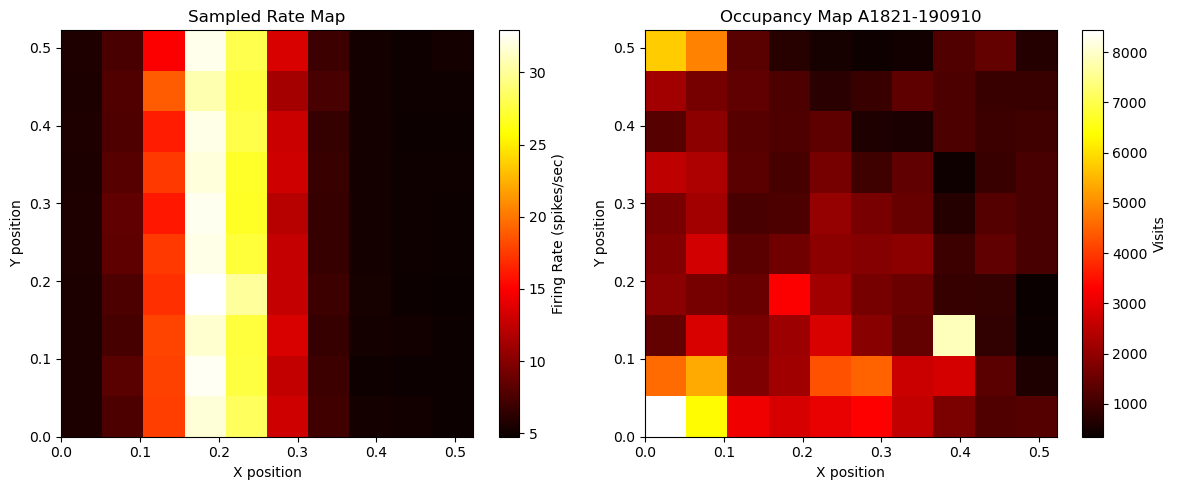

In [37]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5))

# Rate map
im1 = axs[0].imshow(rmap.T, origin='lower', aspect='auto',
                     extent=[s_bins[0], s_bins[-1], s_bins[0], s_bins[-1]],
                     cmap='hot')
axs[0].set_title("Sampled Rate Map")
axs[0].set_xlabel(labels[0])
axs[0].set_ylabel(labels[1])
fig.colorbar(im1, ax=axs[0], label='Firing Rate (spikes/sec)')

# Occupancy map
im2 = axs[1].imshow(occ.T, origin='lower', aspect='auto',
                     extent=[s_bins[0], s_bins[-1], s_bins[0], s_bins[-1]],
                     cmap='hot')
axs[1].set_title(f"Occupancy Map {session}")
axs[1].set_xlabel(labels[0])
axs[1].set_ylabel(labels[1])
fig.colorbar(im2, ax=axs[1], label='Visits')

plt.tight_layout()
plt.savefig('/home/mag/variance-analysis/ideal_rate_map.svg')
plt.show()

In [43]:
def get_splits(
        stim,                  # (s1,s2) from get_tuning_curve
        spike_counts,          # same length as s1/s2
        s_bins,                # bin edges returned by get_tuning_curve
        *,
        min_visits=20,
        seed=None
):
    """
    Randomly halves the samples in each bin → train / test splits.

    Returns
    -------
    train_mean, test_mean : mean spike count in each bin (nan if <min_visits)
    train_occ,  test_occ  : visit counts assigned to each split
    """
    rng = np.random.default_rng(seed)
    num_bins = len(s_bins) - 1
    s1, s2 = stim

    train_mean = np.full((num_bins, num_bins), np.nan)
    test_mean  = np.full((num_bins, num_bins), np.nan)
    all_mean = np.full((num_bins, num_bins), np.nan)
    train_occ  = np.zeros((num_bins, num_bins), dtype=int)
    test_occ   = np.zeros((num_bins, num_bins), dtype=int)

    for i in range(num_bins):
        s1_lo, s1_hi = s_bins[i], s_bins[i + 1]
        mask1 = (s1 > s1_lo) & (s1 <= s1_hi)
        for j in range(num_bins):
            s2_lo, s2_hi = s_bins[j], s_bins[j + 1]
            idx = np.where(mask1 & (s2 > s2_lo) & (s2 <= s2_hi))[0]

            if len(idx) < 2:
                continue

            spikes = spike_counts[idx]
            rng.shuffle(spikes)
            if min_visits < len(idx):
                spikes = spikes[:min_visits] 
            half   = len(spikes) // 2
            train, test = spikes[:half], spikes[half:]

            train_mean[i, j] = np.nan if len(train) == 0 else train.mean()
            test_mean[i,  j] = np.nan if len(test)  == 0 else test.mean()
            all_mean[i, j] = np.nan if len(spikes) == 0 else spikes.mean()
            train_occ[i, j]  = len(train)
            test_occ[i,  j]  = len(test)

    return all_mean, train_mean, test_mean, train_occ, test_occ



In [55]:
_, train_mean, test_mean, train_occ, test_occ = get_splits(stim, spk, s_bins, min_visits=18)

In [39]:
# analysis conditioned on just one hd value
# if you see if a correlation in 1d then there's not a correlation issue
# could be an issue if it's a continuous rate 

condition_single_val = False
val = 7

if condition_single_val:
    train_split = train_split[val]
    train_split = train_split[np.newaxis, :]
    test_split = test_split[val]
    test_split = test_split[np.newaxis, :]

    # and get the occupancies as well?
    train_occ = train_occ[val]
    test_occ = test_occ[val]
    
    print(train_split.shape)
    print(train_occ)
    print(test_occ)

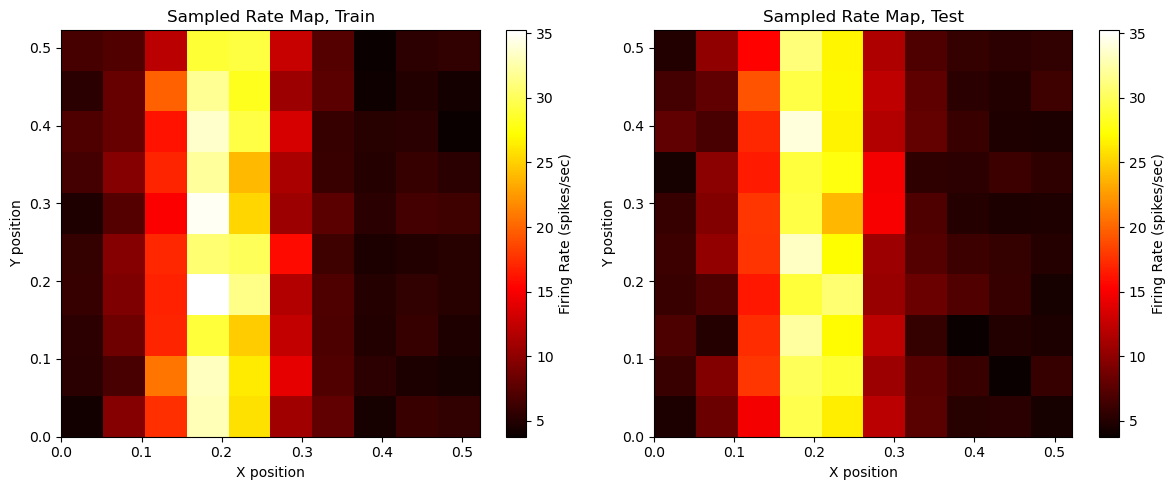

In [57]:
vmin = min(train_mean.min(), test_mean.min())
vmax = max(train_mean.max(), test_mean.max())

# visualize both maps
fig, axs = plt.subplots(1, 2, figsize=(12, 5))

# Rate map
im1 = axs[0].imshow(train_mean.T, origin='lower', aspect='auto',
                     extent=[s_bins[0], s_bins[-1], s_bins[0], s_bins[-1]],
                     cmap='hot', vmin=vmin, vmax=vmax)
axs[0].set_title("Sampled Rate Map, Train")
axs[0].set_xlabel(labels[0])
axs[0].set_ylabel(labels[1])
fig.colorbar(im1, ax=axs[0], label='Firing Rate (spikes/sec)')

# Occupancy map
im2 = axs[1].imshow(test_mean.T, origin='lower', aspect='auto',
                     extent=[s_bins[0], s_bins[-1], s_bins[0], s_bins[-1]],
                     cmap='hot', vmin=vmin, vmax=vmax)
axs[1].set_title("Sampled Rate Map, Test")
axs[1].set_xlabel(labels[0])
axs[1].set_ylabel(labels[1])
fig.colorbar(im2, ax=axs[1], label='Firing Rate (spikes/sec)')

plt.tight_layout()
plt.savefig('/home/mag/variance-analysis/test_train_ideals.svg')
plt.show()

In [50]:
train_occ

array([[5, 5, 5, 5, 5, 5, 5, 5, 5, 5],
       [5, 5, 5, 5, 5, 5, 5, 5, 5, 5],
       [5, 5, 5, 5, 5, 5, 5, 5, 5, 5],
       [5, 5, 5, 5, 5, 5, 5, 5, 5, 5],
       [5, 5, 5, 5, 5, 5, 5, 5, 5, 5],
       [5, 5, 5, 5, 5, 5, 5, 5, 5, 5],
       [5, 5, 5, 5, 5, 5, 5, 5, 5, 5],
       [5, 5, 5, 5, 5, 5, 5, 5, 5, 5],
       [5, 5, 5, 5, 5, 5, 5, 5, 5, 5],
       [5, 5, 5, 5, 5, 5, 5, 5, 5, 5]])

In [411]:
def quantify_variance_1d(heatmap_test, heatmap_train, verbose=False):
    # heatmap_test and heatmap_train are average spikes/sec per behavioral bin
    
    test_mean = np.nanmean(heatmap_test)
    train_mean = np.nanmean(heatmap_train)

    n_bins = heatmap_test.shape[0]

    inter_var_test = np.nansum((heatmap_test - test_mean)**2)
    inter_var_train = np.nansum((heatmap_train - train_mean)**2)

    intra_var_all = np.nansum((heatmap_test - heatmap_train)**2)
    intra_var_means = n_bins * (test_mean - train_mean)**2

    if verbose:
        print(f"sum((test - test_mean)^2)={inter_var_test:.4f}")
        print(f"sum((train - train_mean)^2)={inter_var_train:.4f}")
        print(f"sum((test - train)^2)={intra_var_all:.4f}")
        print(f"n_bins * (test_mean - train_mean)^2={intra_var_means:.4f}")
        print()
    
    estimator = 0.5 * (
        inter_var_test +
        inter_var_train -
        intra_var_all +
        intra_var_means
    )
    
    return estimator, inter_var_test, inter_var_train, intra_var_all, intra_var_means


def quantify_variance(heatmap_test, heatmap_train, axis=0, verbose=False):
    """
    Quantify the variance due to a certain variable in a cross-validated manner.
    heatmaps are 2D, and are average spikes/sec across visits to each behavioral bin.
    Negative values indicate dominance of inherent variance over dimension-explained variance.
    """

    test_mean = np.nanmean(heatmap_test, axis=axis)
    train_mean = np.nanmean(heatmap_train, axis=axis)

    # Expand along `axis` so we can subtract
    if axis == 0:
        test_mean_expanded = test_mean[np.newaxis, :]
        train_mean_expanded = train_mean[np.newaxis, :]
    else:
        test_mean_expanded = test_mean[:, np.newaxis]
        train_mean_expanded = train_mean[:, np.newaxis]

    n_bins = heatmap_test.shape[axis]

    # Now compute the variance terms with occupancy weighting
    inter_var_test = np.nansum((heatmap_test - test_mean_expanded)**2)
    inter_var_train = np.nansum((heatmap_train - train_mean_expanded)**2)

    intra_var_all = np.nansum((heatmap_test - heatmap_train)**2)
    intra_var_means = n_bins * np.nansum((test_mean - train_mean)**2)

    if verbose:
        print(f"axis={axis} sum((test - test_mean)^2)={inter_var_test:.4f}")
        print(f"axis={axis} sum((train - train_mean)^2)={inter_var_train:.4f}")
        print(f"axis={axis} sum((test - train)^2)={intra_var_all:.4f}")
        print(f"axis={axis} n_bins * sum((test_mean - train_mean)^2)={intra_var_means:.4f}")
        print()
    
    estimator = 0.5 * (
        inter_var_test +
        inter_var_train -
        intra_var_all +
        intra_var_means
    )
    
    return estimator, inter_var_test, inter_var_train, intra_var_all, intra_var_means


def quantify_variance_weighted_norm(heatmap_test, heatmap_train,
                                    occupancy_test, occupancy_train,
                                    axis=0, verbose=False):
    """
    Quantify the variance due to a certain variable in a cross-validated manner,
    incorporating occupancy weighting with normalization.
    
    heatmap_test, heatmap_train: 2D arrays of mean spikes/sec per behavioral bin.
    occupancy_test, occupancy_train: 2D arrays of visit counts for each bin.
    
    The normalization accounts for the fact that the heatmaps are already averaged,
    so that in the uniform case the estimator matches the original.
    """
    # Compute occupancy-weighted means along the specified axis.
    sum_occ_test = np.nansum(occupancy_test, axis=axis)
    sum_occ_train = np.nansum(occupancy_train, axis=axis)
    test_mean = np.nansum(occupancy_test * heatmap_test, axis=axis) / sum_occ_test
    train_mean = np.nansum(occupancy_train * heatmap_train, axis=axis) / sum_occ_train

    # Expand the means so we can subtract along the axis.
    if axis == 0:
        test_mean_expanded = test_mean[np.newaxis, :]
        train_mean_expanded = train_mean[np.newaxis, :]
    else:
        test_mean_expanded = test_mean[:, np.newaxis]
        train_mean_expanded = train_mean[:, np.newaxis]

    # Compute average occupancy (a normalization factor).
    avg_occ_test = np.nanmean(occupancy_test)
    avg_occ_train = np.nanmean(occupancy_train)
    # Use the average of the two.
    c = (avg_occ_test + avg_occ_train) / 2.0

    # Compute weighted sums of squared differences, then normalize by c.
    inter_var_test = np.nansum(occupancy_test * (heatmap_test - test_mean_expanded)**2) / c
    inter_var_train = np.nansum(occupancy_train * (heatmap_train - train_mean_expanded)**2) / c

    # For the pairwise differences, average the occupancies and normalize.
    occupancy_avg = (occupancy_test + occupancy_train) / 2.0
    intra_var_all = np.nansum(occupancy_avg * (heatmap_test - heatmap_train)**2) / c

    # For the difference of means, we want an effective n_bins.
    if axis == 0:
        raw_weights = np.nansum(occupancy_avg, axis=0)
    else:
        raw_weights = np.nansum(occupancy_avg, axis=1)
    n_bins_eff = len(raw_weights)
    # Normalize so that the weights sum to n_bins_eff.
    weights_norm = raw_weights / np.nansum(raw_weights) * n_bins_eff
    intra_var_means = np.nansum(weights_norm * (test_mean - train_mean)**2)

    if verbose:
        print(f"axis={axis} weighted sum((test - test_mean)^2)/c={inter_var_test:.4f}")
        print(f"axis={axis} weighted sum((train - train_mean)^2)/c={inter_var_train:.4f}")
        print(f"axis={axis} weighted sum((test - train)^2)/c={intra_var_all:.4f}")
        print(f"axis={axis} normalized sum(weights*(test_mean - train_mean)^2)={intra_var_means:.4f}")
        print()

    estimator = 0.5 * (inter_var_test + inter_var_train - intra_var_all + intra_var_means)
    return estimator, inter_var_test, inter_var_train, intra_var_all, intra_var_means


In [260]:
space = (limits[1] - limits[0]) / (2 * num_bins)
space

0.0087074

In [271]:
num_bins

30

In [270]:
bin_edges = np.linspace(limits[0], limits[1], num=num_bins + 1)
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
s1_centers, s2_centers = np.meshgrid(bin_centers, bin_centers, indexing='ij')  

(30, 30)

In [275]:
train_split.shape

(15, 15)

In [483]:
from scipy.interpolate import LinearNDInterpolator

# base params
num_bins = [5, 10, 15, 25, 35, 50]
n_interp_bins = 200


# sampling
curves = 1
splits = 100

all_interp_var = np.zeros((len(num_bins), splits))
explained_s1 = np.zeros((len(num_bins), curves, splits))
explained_s2 = np.zeros((len(num_bins), curves, splits))

for nn, n_bins in enumerate(num_bins):
    # calculate the bin centers
    bin_edges = np.linspace(limits[0], limits[1], num=n_bins + 1)
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
    s1_centers, s2_centers = np.meshgrid(bin_centers, bin_centers, indexing='ij')
    points = np.stack([s1_centers.ravel(), s2_centers.ravel()], axis=1)
    
    # and the finer bin centers
    interp_bin_edges = np.linspace(limits[0], limits[1], num=n_interp_bins + 1)
    interp_bin_centers = (interp_bin_edges[:-1] + interp_bin_edges[1:]) / 2
    interp_s1_centers, interp_s2_centers = np.meshgrid(interp_bin_centers, interp_bin_centers, indexing='ij')
    
    # and let's get the finer rate map for normalization
    finer_total, _, _, _, _ = get_splits(
        stim, 
        spikes, 
        interp_bin_edges,
        min_visits=2,        
        seed=429              
    )
    
    
    for i in tqdm(range(curves)):
        # really for right now if uniform is false we just get the normal spikes from this
        # TODO is there an additional source of randomness?
        stim, spikes, rate_map, occ, s_bins = get_tuning_curve(
            stimuli,              
            limits,
            stimulus_type='xy',    
            uniform=False,
            dead_center=False,
            num_bins=n_bins,
            seed=i
        )
        for j in range(splits):
            total, train_split, test_split, _, _ = get_splits(
                stim, # x, y locations
                spikes, # spikes/sec at this location
                s_bins,
                min_visits=16,        
                seed=j               
            )
    
            s1, s2 = stim
            raw_points = np.stack([s1, s2], axis=1)

            train_func = LinearNDInterpolator(points, train_split.ravel())
            test_func = LinearNDInterpolator(points, test_split.ravel())
    
            # I think now you just evaluate these both at 200 bins 
            train_split = train_func(interp_s1_centers, interp_s2_centers)
            test_split = test_func(interp_s1_centers, interp_s2_centers)
    
            #total_interp = LinearNDInterpolator(raw_points, spikes, fill_value=np.nan)
            #interp_points = total_interp(points) # find the interpolated value at the center of the bin
    
            # need to normalize wrt the 200 bins and not the smaller amount of bins
            
            #grand_mean = np.nanmean(total)
            #total_ss = np.nansum((total - grand_mean)**2)
            # write this in the text as an equation for the normalization procedure
            
            '''
            train_split, test_split = create_interpolated_splits(
                stim,
                spikes,
                limits,
                num_bins,
                seed=j
            )
            total_ss = 1.
            '''
    
            #print('Total variance =', total_ss)
            #print('Interp - train =', np.nansum((interp_points - train_split.ravel())**2))
            #print('Interp - test =', np.nansum((interp_points - test_split.ravel())**2))
            #total_variance = np.nanmean((interp_points - total.ravel())**2)
            #all_interp_var[nn] = total_variance
            #print('Interp - total =', total_variance)
    
            explained_s1[nn, i, j] = (quantify_variance(test_split, train_split, axis=0, verbose=False)[0]) #/ total_ss
            explained_s2[nn, i, j] = (quantify_variance(test_split, train_split, axis=1, verbose=False)[0]) #/ total_ss

# firing rate map w infinite res, piecewise linear
        

  0%|                                                                                          | 0/1 [00:00<?, ?it/s]/tmp/ipykernel_3959672/263739660.py:151: RuntimeWarning: invalid value encountered in divide
  rate_map /= occ
/tmp/ipykernel_3959672/219009620.py:39: RuntimeWarning: Mean of empty slice
  test_mean = np.nanmean(heatmap_test, axis=axis)
/tmp/ipykernel_3959672/219009620.py:40: RuntimeWarning: Mean of empty slice
  train_mean = np.nanmean(heatmap_train, axis=axis)
100%|██████████████████████████████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.94s/it]


In [475]:
explained_s1.shape

(6, 30, 30)

In [485]:
np.mean(all_interp_var, axis=1) 

array([ 8.6004359 , 17.03173114, 10.40504307,  6.84213706,  7.88321722,
        9.11960637])

In [473]:
np.mean(explained_s2, axis=(1,2))

array([-0.24647274, -0.06631163, -0.07768234, -0.03942361,  0.01965997,
        0.10588851])

ValueError: x and y must be the same size

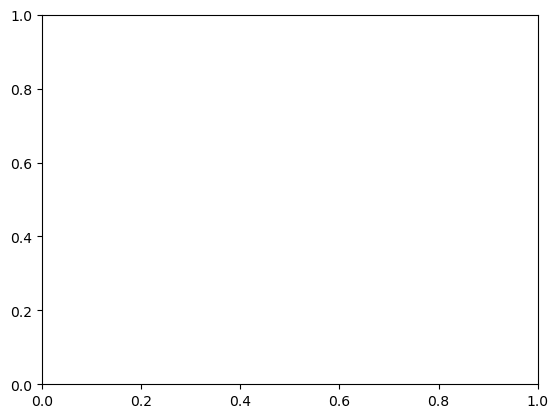

In [490]:
# with interp factored in
plt.scatter(np.mean(all_interp_var, axis=1), np.mean(explained_s2, axis=1))
plt.show()

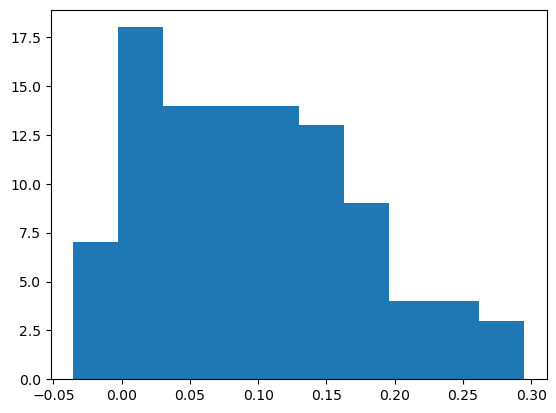

In [454]:
# with normalization 
plt.hist(explained_s2.flatten())
plt.show()

# this is with n_bins = 25

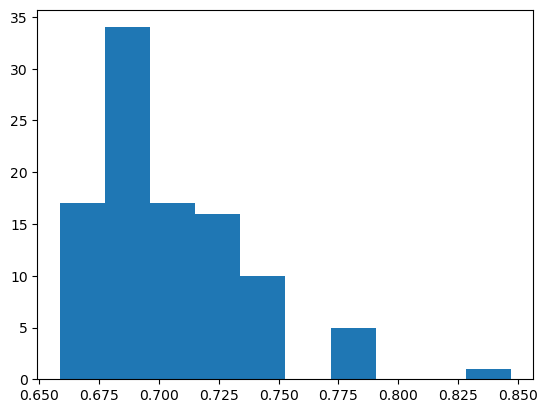

In [455]:
# with normalization
plt.hist(explained_s1.flatten())
plt.show()

In [408]:

from scipy.interpolate import LinearNDInterpolator

# base params
num_bins = 15
n_interp_bins = 15

# sampling
curves = 20
splits = 40

explained_s1 = np.zeros((curves, splits))
explained_s2 = np.zeros((curves, splits))

# calculate the bin centers
bin_edges = np.linspace(limits[0], limits[1], num=num_bins + 1)
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
s1_centers, s2_centers = np.meshgrid(bin_centers, bin_centers, indexing='ij')
points = np.stack([s1_centers.ravel(), s2_centers.ravel()], axis=1)

# and the finer bin centers
interp_bin_edges = np.linspace(limits[0], limits[1], num=n_interp_bins + 1)
interp_bin_centers = (interp_bin_edges[:-1] + interp_bin_edges[1:]) / 2
interp_s1_centers, interp_s2_centers = np.meshgrid(interp_bin_centers, interp_bin_centers, indexing='ij')

for i in tqdm(range(curves)):
    stim, spikes, rate_map, occ, s_bins = get_tuning_curve(
        stimuli,              
        limits,
        stimulus_type='xy',    
        uniform=False,
        dead_center=False,
        num_bins=num_bins,
        seed=i
    )
    for j in range(splits):
        # --- The Correct Approach ---
    
        # 1. Create a train/test split of the RAW data indices
        n_samples = len(stim[0])
        rng = np.random.default_rng(seed=j)
        shuffled_indices = rng.permutation(n_samples)
        train_indices = shuffled_indices[:n_samples // 2]
        test_indices = shuffled_indices[n_samples // 2:]
    
        # 2. Select the raw data points for each split
        s1, s2 = stim
        raw_points = np.stack([s1, s2], axis=1) # Shape: (n_samples, 2)
        
        train_points_raw = raw_points[train_indices]
        train_spikes_raw = spikes[train_indices]
    
        test_points_raw = raw_points[test_indices]
        test_spikes_raw = spikes[test_indices]
    
        # 3. Build two INDEPENDENT interpolators from the raw data
        # This avoids the biased bin-averaging of get_splits()
        # Note: We add a fill_value to handle query points outside the data hull
        train_func = LinearNDInterpolator(train_points_raw, train_spikes_raw, fill_value=np.nan)
        test_func = LinearNDInterpolator(test_points_raw, test_spikes_raw, fill_value=np.nan)
    
        # 4. Evaluate both functions on your high-resolution grid of centers
        # The evaluation points need to be in the correct (N, 2) shape
        interp_points = np.stack([interp_s1_centers.ravel(), interp_s2_centers.ravel()], axis=1)
        
        train_high_res_flat = train_func(interp_points)
        test_high_res_flat = test_func(interp_points)
    
        # Reshape back to 2D heatmaps
        train_high_res = train_high_res_flat.reshape(n_interp_bins, n_interp_bins)
        test_high_res = test_high_res_flat.reshape(n_interp_bins, n_interp_bins)
        
        # 5. Proceed with your variance quantification
        # Note: We can't use the old total_ss. The normalization should be against the variance
        # of the high-res maps themselves, or simply set to 1 if you want the raw variance.
        #heatmap_avg = 0.5 * (train_high_res + test_high_res)
        #total_ss = np.nansum((heatmap_avg - np.nanmean(heatmap_avg))**2)
        #if total_ss == 0: total_ss = 1.0 # Avoid division by zero
        
        explained_s1[i, j] = quantify_variance(test_high_res, train_high_res, axis=0)[0]# / total_ss
        explained_s2[i, j] = quantify_variance(test_high_res, train_high_res, axis=1)[0]# / total_ss


  0%|                                                                                         | 0/20 [00:00<?, ?it/s]/tmp/ipykernel_3959672/263739660.py:151: RuntimeWarning: invalid value encountered in divide
  rate_map /= occ
/tmp/ipykernel_3959672/219009620.py:39: RuntimeWarning: Mean of empty slice
  test_mean = np.nanmean(heatmap_test, axis=axis)
/tmp/ipykernel_3959672/219009620.py:40: RuntimeWarning: Mean of empty slice
  train_mean = np.nanmean(heatmap_train, axis=axis)
100%|████████████████████████████████████████████████████████████████████████████████| 20/20 [00:25<00:00,  1.27s/it]


In [352]:
from scipy.interpolate import LinearNDInterpolator

# base params
n_bin_sizes = [5, 15, 30, 70]
l = len(n_bin_sizes)

# sampling
curves = 1
splits = 50

explained_s1_unnorm = [np.zeros((curves, splits)) for _ in range(l)]
explained_s2_unnorm = [np.zeros((curves, splits)) for _ in range(l)]
explained_s1_norm = [np.zeros((curves, splits)) for _ in range(l)]
explained_s2_norm = [np.zeros((curves, splits)) for _ in range(l)]

for k in tqdm(range(l)):
    for i in range(curves):
        # TODO is there an additional source of randomness?
        print("Bin size", n_bin_sizes[k])
        stim, spikes, rate_map, occ, s_bins = get_tuning_curve(
            stimuli,              
            limits,
            stimulus_type='xy',    
            uniform=False,
            dead_center=False,
            num_bins=n_bin_sizes[k],
            seed=i
        )
        for j in range(splits):
            total, train_split, test_split, _, _ = get_splits(
                stim, # x, y locations
                spikes, # spikes/sec at this location
                s_bins,
                min_visits=16,        
                seed=j               
            )
    
            '''
            train_func = LinearNDInterpolator(points, train_split.ravel())
            test_func = LinearNDInterpolator(points, test_split.ravel())
    
            # I think now you just evaluate these both at 200 bins 
            train_points = train_func(interp_s1_centers, interp_s2_centers)
            test_points = test_func(interp_s1_centers, interp_s2_centers)
            '''
            
            grand_mean = np.nanmean(total)
            total_ss = np.nansum((total - grand_mean)**2)
            
            '''
            train_split, test_split = create_interpolated_splits(
                stim,
                spikes,
                limits,
                num_bins,
                seed=j
            )
            total_ss = 1.
            '''
    
            explained_s1_unnorm[k][i, j] = quantify_variance(test_split, train_split, axis=0, verbose=False)[0]
            explained_s2_unnorm[k][i, j] = quantify_variance(test_split, train_split, axis=1, verbose=False)[0]
            explained_s1_norm[k][i, j] = explained_s1_unnorm[k][i, j] / total_ss
            explained_s2_norm[k][i, j] = explained_s2_unnorm[k][i, j] / total_ss

# firing rate map w infinite res, piecewise linear
        

  0%|                                                                                          | 0/4 [00:00<?, ?it/s]/tmp/ipykernel_3959672/263739660.py:151: RuntimeWarning: invalid value encountered in divide
  rate_map /= occ
/tmp/ipykernel_3959672/219009620.py:39: RuntimeWarning: Mean of empty slice
  test_mean = np.nanmean(heatmap_test, axis=axis)
/tmp/ipykernel_3959672/219009620.py:40: RuntimeWarning: Mean of empty slice
  train_mean = np.nanmean(heatmap_train, axis=axis)
 25%|████████████████████▌                                                             | 1/4 [00:00<00:00,  7.92it/s]

Bin size 5
Bin size 15


 50%|█████████████████████████████████████████                                         | 2/4 [00:00<00:00,  3.32it/s]

Bin size 30


 75%|█████████████████████████████████████████████████████████████▌                    | 3/4 [00:01<00:00,  1.22it/s]

Bin size 70


100%|██████████████████████████████████████████████████████████████████████████████████| 4/4 [00:07<00:00,  1.86s/it]


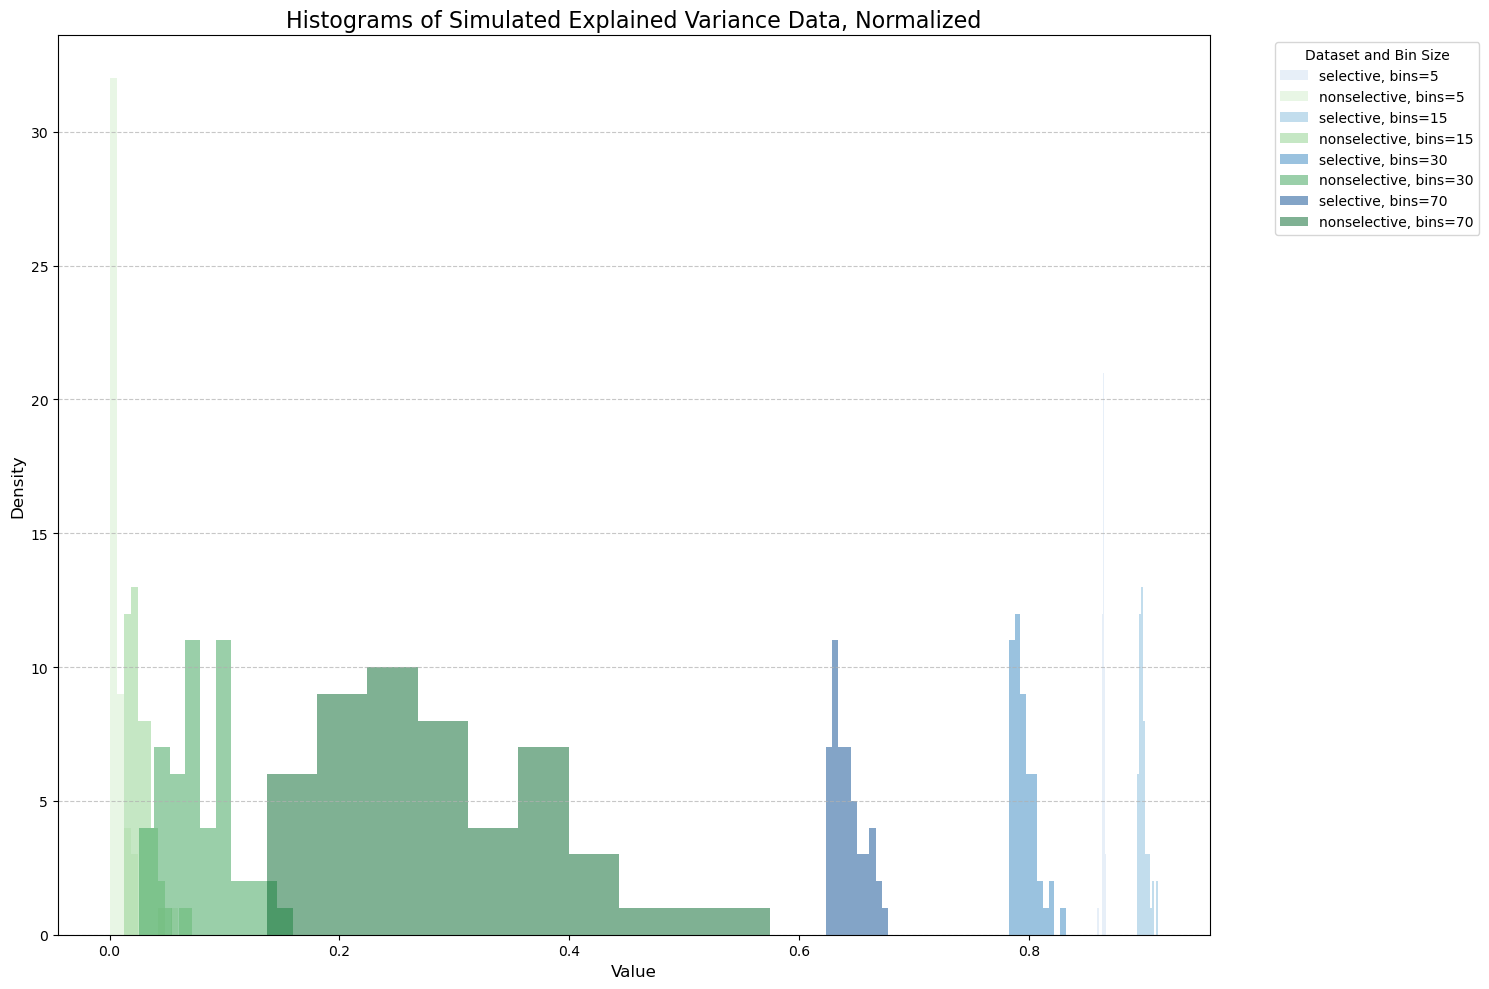

In [368]:
plt.figure(figsize=(15, 10))

# Define color schemes for the histograms
colors_s1 = plt.cm.Blues(np.linspace(0.2, 0.9, l))
colors_s2 = plt.cm.Greens(np.linspace(0.2, 0.9, l))

# Plot all the histograms on the same axes
for i in range(l):
    #plt.hist(explained_s1_unnorm[i].flatten(), color=colors_s1[i], alpha=0.5, label=f'selective, bins={n_bin_sizes[i]}')
    #plt.hist(explained_s2_unnorm[i].flatten(), color=colors_s2[i], alpha=0.5, label=f'nonselective, bins={n_bin_sizes[i]}')
    plt.hist(explained_s1_norm[i].flatten(), color=colors_s1[i], alpha=0.5, label=f'selective, bins={n_bin_sizes[i]}')
    plt.hist(explained_s2_norm[i].flatten(), color=colors_s2[i], alpha=0.5, label=f'nonselective, bins={n_bin_sizes[i]}')

# Add plot details
plt.title('Histograms of Simulated Explained Variance Data, Normalized', fontsize=16)
plt.xlabel('Value', fontsize=12)
plt.ylabel('Density', fontsize=12)
plt.legend(title='Dataset and Bin Size', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()

plt.savefig('/home/mag/variance-analysis/figs/norm.png', dpi=300)

In [194]:
import numpy as np
import pandas as pd
from tqdm import tqdm

def variability_vs_bins(
    stimuli,
    limits,
    bin_list,          # iterable of ints, e.g. range(5, 65, 5)
    *,
    curves=5,          # how many synthetic “neurons”
    splits=50,         # how many CV repetitions per neuron
    min_visits=10,     # same as in your get_splits call
    seed_base=0        # so every run is reproducible
):
    """
    Sweep over different num_bins values and collect all variance-estimator terms.

    Returns
    -------
    pd.DataFrame with columns:
        ['num_bins', 'axis', 'curve', 'split',
         'estimator', 'inter_test', 'inter_train',
         'intra_all', 'intra_means']
    """
    records = []

    for nb in tqdm(bin_list, desc="num_bins"):
        # ---- generate a new “ideal” neuron for each curve -------------
        for i in range(curves):
            stim, spikes, rate_map, occ, s_bins = get_tuning_curve(
                stimuli,
                limits,
                stimulus_type='xy',
                uniform=False,
                dead_center=False,
                num_bins=nb,
                seed=seed_base + i
            )

            # ---- cross-validated splits for that neuron --------------
            for j in range(splits):
                train_hm, test_hm, *_ = get_splits(
                    stim, spikes, s_bins,     # s_bins is in *_ above
                    min_visits=min_visits,
                    seed=seed_base + j
                )

                # axis 0 (vary s1, average over s2)
                est0, itest0, itrain0, iall0, imean0 = quantify_variance(
                    test_hm, train_hm, axis=0)
                records.append(
                    dict(num_bins=nb, axis=0, curve=i, split=j,
                         estimator=est0,
                         inter_test=itest0, inter_train=itrain0,
                         intra_all=iall0, intra_means=imean0)
                )

                # axis 1 (vary s2, average over s1)
                est1, itest1, itrain1, iall1, imean1 = quantify_variance(
                    test_hm, train_hm, axis=1)
                records.append(
                    dict(num_bins=nb, axis=1, curve=i, split=j,
                         estimator=est1,
                         inter_test=itest1, inter_train=itrain1,
                         intra_all=iall1, intra_means=imean1)
                )

    return pd.DataFrame.from_records(records)

# ---------------------------------------------------------------------
# EXAMPLE USAGE --------------------------------------------------------
# Suppose `stimuli` (tuple of arrays) and `limits` are already defined.
bin_grid = range(5, 50, 5)          # 5, 10, …, 60
capped_df = variability_vs_bins(
    stimuli, limits, bin_grid,
    curves=1, splits=50,            # dial these up or down at will
    min_visits=10
)

# Now you can, for instance:
#   df.groupby(['num_bins', 'axis'])['estimator'].mean().unstack()
# or
#   sns.lineplot(data=df, x='num_bins', y='inter_test', hue='axis')


num_bins:  33%|████████████████████████                                                | 3/9 [00:11<00:26,  4.40s/it]/tmp/ipykernel_3959672/263739660.py:151: RuntimeWarning: invalid value encountered in divide
  rate_map /= occ
num_bins: 100%|████████████████████████████████████████████████████████████████████████| 9/9 [03:25<00:00, 22.78s/it]


<Axes: xlabel='num_bins', ylabel='estimator'>

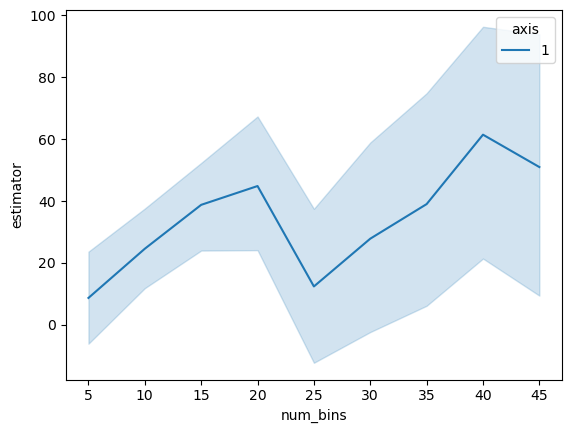

In [195]:

sns.lineplot(data=capped_df[capped_df.axis == 1], x='num_bins', y='estimator', hue='axis')


In [ ]:
import seaborn as sns
sns.lineplot(data=df, x='num_bins', y='inter_test', hue='axis')

In [172]:
df

,num_bins,axis,curve,split,estimator,inter_test,inter_train,intra_all,intra_means
0,5,0,0,0,2029.360000,2416.864000,1965.760000,417.80,93.896000
1,5,1,0,0,119.616000,251.504000,309.840000,417.80,95.688000
2,5,0,0,1,1997.864000,2128.368000,2191.936000,415.36,90.784000
3,5,1,0,1,-6.984000,142.784000,247.072000,415.36,11.536000
4,5,0,0,2,1844.248000,2268.080000,1644.144000,331.48,107.752000
...,...,...,...,...,...,...,...,...,...
1195,60,1,0,47,151.789219,7532.055706,8052.184235,15727.60,446.938498
1196,60,0,0,48,293304.851195,300460.426464,301827.359484,16070.56,392.476441
1197,60,1,0,48,-63.870802,7720.461642,7601.661527,16070.56,620.695227
1198,60,0,0,49,295064.504327,305358.004725,299967.860882,15690.84,493.983047


<Axes: xlabel='num_bins', ylabel='estimator'>

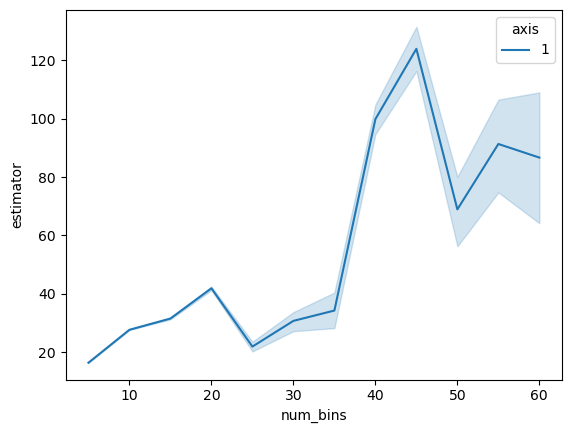

In [190]:
sns.lineplot(data=df[df.axis == 1], x='num_bins', y='estimator', hue='axis')

In [196]:
# --- variance across splits (ignoring which synthetic neuron it came from) ----
var_estimator = (
    df                         # the DataFrame returned by variability_vs_bins
    .groupby(['num_bins', 'axis'])['estimator']  # pick any column you like
    .var()                     # sample variance across all splits and curves
    .unstack()                 # axis on separate columns for quick plotting
)

print(var_estimator.head())


axis               0          1
num_bins                       
5           0.004024   0.004888
10          0.085086   0.087389
15          0.903034   0.923403
20          7.017728   4.979056
25        142.269063  33.814244


## 1D test only

Recreating the issue we saw with the previous 1D thing. So...
- base value across the 1D slice is already high
- there's uneven sampling across this (test various levels of "uneven")
- might also wanna grab real movement statistics from each slice and just see what happens with that?
- I'm skeptical that that's the issue. So what is?


In [71]:
def get_rate_map(sample_scheme='uniform', seed=413, stimuli=None, stim_idx=-1):
    rng = np.random.default_rng(seed)
    base_val = 30.
    l = 10

    spikes = [[]] * l
    rate_map = np.full(l, np.nan)
    n_visits = 500

    if sample_scheme == 'uniform':
        for i in range(l):
            spikes[i] = rng.poisson(base_val, n_visits)
            rate_map[i] = np.mean(spikes[i])
    elif sample_scheme == 'poisson':
        for i in range(l):
            n_visit = rng.poisson(n_visits)
            spikes[i] = rng.poisson(base_val, n_visit)
            rate_map[i] = np.mean(spikes[i])
    elif sample_scheme == 'decreasing':
        for i in range(l):
            n_visit = int(n_visits * (1/l))
            spikes[i] = rng.poisson(base_val, n_visit)
            rate_map[i] = np.mean(spikes[i])
    elif sample_scheme == 'stim':
        visits = np.histogram2d(stimuli[0], stimuli[1], bins=l)[0][stim_idx] # you have 0 clue if this is correct or not lol
        # define this on the continuous range that your visits are from, then the rate map will be a histogram
        for i in range(l):
            n_visit = int(visits[i])
            spikes[i] = rng.poisson(base_val, n_visit) # this doesn't have the internal stimuli, for the record. we didn't think that made a big diff prev though
            rate_map[i] = np.mean(spikes[i])
    else:
        return None

    return rate_map, spikes

def get_folds(spikes, min_visits=2, cap=False, seed=413):
    rng = np.random.default_rng(seed)
    
    l = len(spikes)
    fold0 = np.full(l, np.nan)
    fold1 = np.full(l, np.nan)
    fold_occ = np.full(l, 0) # split evenly, so this is for both folds
    
    for i in range(l):
        if len(spikes[i]) < min_visits:
            continue

        visits = spikes[i]
        rng.shuffle(visits)

        if cap:
            visits = visits[:min_visits]
        
        half = len(visits) // 2
        fold0[i] = np.mean(visits[:half])
        if len(visits) % 2 == 0:
            fold1[i] = np.mean(visits[half:])
        else:
            fold1[i] = np.mean(visits[half:-1])

        fold_occ[i] = half

    return fold0, fold1, fold_occ

            

In [59]:
rmap.shape

(10, 10)

In [70]:
rmap[3]


array([31.73965334, 32.52240185, 31.48043376, 32.90806697, 32.15126582,
       32.43229167, 31.81233001, 32.20272572, 30.68393327, 32.2972973 ])

In [61]:
rate_map, spikes = get_rate_map(sample_scheme='stim', seed=0, stimuli=stimuli, stim_idx=6)
#train_split, test_split, occ = get_folds(spikes, min_visits=2, seed=0)

rate_map

array([49.94463938, 50.11879699, 50.04656011, 50.17465753, 49.93204868,
       50.00987306, 50.06544687, 50.01935484, 49.88342165, 49.84280303])

In [127]:

# sampling
curves = 50
splits = 50

explained_s1 = np.zeros((curves, splits))

for i in tqdm(range(curves)):
    rate_map, spikes = get_rate_map(sample_scheme='stim', seed=i, stimuli=stimuli, stim_idx=12)
    for j in range(splits):
        train_split, test_split, occ = get_folds(spikes, min_visits=2, seed=j)
        explained_s1[i, j] = quantify_variance_1d(test_split, train_split, verbose=False)[0]
        

100%|████████████████████████████████████████████████████████████████████████████████| 50/50 [00:00<00:00, 53.12it/s]


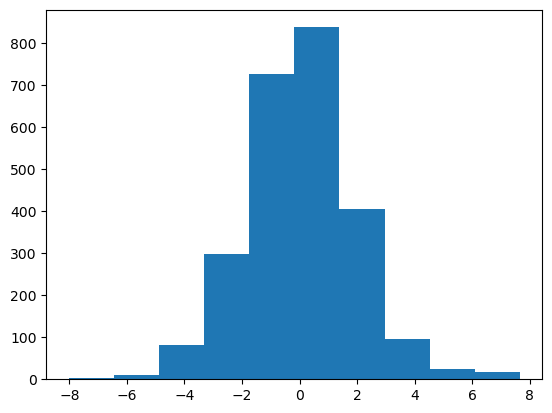

In [128]:

plt.hist(explained_s1.flatten())
plt.show()


In [107]:
np.histogram2d(stimuli[0], stimuli[1], bins=17)[0]

array([[ 606., 1132.,  566.,  347.,  259.,  257.,  439.,  381.,  214.,
         217.,  488.,  280.,  274.,  236.,  312.,  831.,  520.],
       [1493., 1552., 1182.,  487.,  358.,  347.,  585.,  551.,  419.,
         558.,  664.,  729.,  547.,  520.,  633.,  849., 1704.],
       [ 943.,  997., 1037.,  831.,  514.,  543.,  367.,  632.,  468.,
         492.,  445.,  626.,  365.,  642.,  476.,  549., 1060.],
       [ 665.,  700.,  651.,  324.,  281.,  313.,  308.,  481.,  747.,
         452.,  446.,  390.,  352.,  395.,  190.,  388.,  512.],
       [ 612.,  488.,  483.,  534.,  591.,  489.,  403.,  347.,  354.,
         214.,  313.,  434.,  282.,  405.,  434.,  314.,  223.],
       [ 739.,  524.,  525.,  443.,  635.,  695.,  387.,  388.,  237.,
         268.,  296.,  302.,  342.,  228.,  414.,  295.,  108.],
       [ 520.,  637.,  578.,  479.,  609., 1021.,  813.,  522.,  449.,
         440.,  341.,  382.,  436.,  155.,  149.,  256.,  147.],
       [ 610.,  632.,  786.,  598.,  758.,  468.

So when we looked at this last time we figured out that there's something going on with the within bin variation and I'm not sure how to take that

If you pin every visit to the center of the bin, the problem appears to disappear. 

When you make the bin size a lot smaller, the median variance explained across random datasets for a nonselective dimension shifts higher because the first two terms increase (which makes sense) and of course the third term would not increase since it has nothing to do with a mean

well that makes sense for why the spread is larger but does it make sense for why the first two terms would be larger with a smaller bin?
well, you'd have one mean across the dim and then a bunch of bins against it so you'd just have more points to consider there right? 
and the means of each bin, since they're smaller, are going to be more dominated by outliers/noise? and then the 

uhh I don't really understand why the third term shouldn't also increase. What does our occ look like?

literally just pay attention for another half an hour and then you can go home

